# Fairness checks: is our backtest score honest?

This notebook runs the two checks in `ml/scripts/` **one step at a time**, so you can see what each function does and look at the data in between:

| Part | Script | Question it answers | Needs |
|---|---|---|---|
| 1 | `leakage_test.py` | Does any forecast secretly use data from after the date it was made? | Python only (~5 min, or ~1 min with fewer models) |
| 2 | `fairness_stats.py` | Is the score significant, stable and well calibrated? | The Docker stack running (`docker compose up`), or the results of Part 1 |
| 3 | *your script* | Run and test your own script from here | — |

**How to open it**

```bash
cd ml
python3 -m pip install notebook matplotlib      # once
python3 -m notebook notebooks/fairness_checks.ipynb
```

(or open the file in VS Code and pick a Python 3.11 kernel). Run the cells top to bottom with **Shift + Enter**.

The Python packages in `ml/requirements.txt` plus PyTorch must be installed on your laptop: `python3 -m pip install -r requirements.txt torch`.

## 0. Setup

Finds the `ml/` folder, makes `coe_ml` and the scripts importable, and turns on **autoreload**: if you edit a script and save it, the next cell you run uses the new version without restarting the notebook.

In [11]:
%load_ext autoreload
%autoreload 2

import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ML_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "coe_ml").is_dir())
for path in (ML_DIR, ML_DIR / "scripts"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import leakage_test
import fairness_stats
from coe_ml import evaluation
from coe_ml.features import build_panel

pd.set_option("display.width", 140)
print("ml folder:", ML_DIR)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
ml folder: /Users/sarah/Desktop/DSA2111-COE-Forecasting/ml


## Part 1 — Leakage test

**Idea.** The backtest pretends it is an old date, forecasts forward, then compares with what really happened. If the code accidentally let a forecast *see* later data, the score would look better than it really is.

To catch that, we run the whole backtest twice:

1. on the real data, and
2. with every premium and bid count **after a cut-off date** replaced by random nonsense.

A forecast made **before** the cut-off may only use data up to its own date, so it must come out **exactly the same** in both runs. Forecasts made **after** the cut-off should change (the control: it proves the test notices when data is used).

### 1.1 Load the data
`load()` reads the committed data snapshot, builds the model panel (one row per category per bidding exercise) and picks the cut-off in the middle of the 72-exercise test period.

In [12]:
coe, macro, panel, cfg, cut = leakage_test.load()

exercise = panel.drop_duplicates("time_idx").set_index("time_idx")
test_start = cut - cfg.backtest.test_exercises // 2
label = lambda t: f"{exercise.loc[t, 'month']:%b %Y} #{exercise.loc[t, 'bidding_no']}"
print(f"{panel['time_idx'].nunique()} bidding exercises x {panel['category'].nunique()} categories = {len(panel)} rows")
print(f"training period: {label(0)} .. {label(test_start - 1)}")
print(f"test period:     {label(test_start)} .. {label(panel['time_idx'].max())}")
print(f"cut-off:         {label(cut)} (exercise {cut})")
panel[["category", "time_idx", "month", "bidding_no", "quota", "bids_received", "premium"]].tail()

396 bidding exercises x 5 categories = 1980 rows
training period: Jan 2010 #1 .. Sep 2023 #2
test period:     Oct 2023 #1 .. Sep 2026 #2
cut-off:         Apr 2025 #1 (exercise 360)


,category,time_idx,month,bidding_no,quota,bids_received,premium
1975,E,391,2026-07-01,2,263,450,129971
1976,E,392,2026-08-01,1,254,443,131000
1977,E,393,2026-08-01,2,254,467,135000
1978,E,394,2026-09-01,1,300,513,137890
1979,E,395,2026-09-01,2,269,431,137000


### 1.2 Scramble everything after the cut-off
`scramble_after()` multiplies each premium and bid count after the cut-off by a random number between 0.3 and 3. Here is Cat A around the cut-off, real vs scrambled:

In [13]:
scrambled, mask = leakage_test.scramble_after(coe, panel, cut)
print(f"scrambled {mask.sum()} of {len(coe)} rows")

cut_month = exercise.loc[cut, "month"]
side_by_side = coe.assign(premium_scrambled=scrambled["premium"], changed=mask)
side_by_side[(side_by_side["category"] == "A") & (pd.to_datetime(side_by_side["month"]).between(
    cut_month - pd.DateOffset(months=2), cut_month + pd.DateOffset(months=2)))][
    ["month", "bidding_no", "premium", "premium_scrambled", "changed"]]

scrambled 175 of 1980 rows


,month,bidding_no,premium,premium_scrambled,changed
1780,2025-02-01,1,85000,85000,False
1785,2025-02-01,2,92850,92850,False
1790,2025-03-01,1,92730,92730,False
1795,2025-03-01,2,94502,94502,False
1800,2025-04-01,1,97724,97724,False
1805,2025-04-01,2,99500,167351,True
1810,2025-05-01,1,103009,148640,True
1815,2025-05-01,2,102501,239287,True
1820,2025-06-01,1,96999,147870,True
1825,2025-06-01,2,98124,228235,True


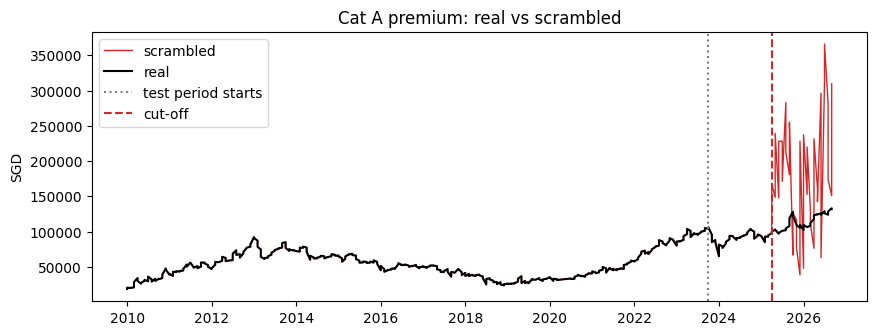

In [14]:
real_a = build_panel(coe, macro).query("category == 'A'")
fake_a = build_panel(scrambled, macro).query("category == 'A'")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(fake_a["month"], fake_a["premium"], color="tab:red", lw=1, label="scrambled")
ax.plot(real_a["month"], real_a["premium"], color="black", lw=1.5, label="real")
ax.axvline(exercise.loc[test_start, "month"], color="grey", ls=":", label="test period starts")
ax.axvline(cut_month, color="tab:red", ls="--", label="cut-off")
ax.set(title="Cat A premium: real vs scrambled", ylabel="SGD")
ax.legend(); plt.show()

### 1.3 Run the backtest twice
This is the slow step. `MODELS` picks which models to test: all six take about 5 minutes on a laptop; `["naive", "arima"]` takes about a minute. The settings are `fast_config()` (fewer training epochs) because we are testing *what data the code uses*, not accuracy.

In [15]:
MODELS = leakage_test.MODELS        # e.g. ["naive", "arima"] for a quick run

started = time.time()
real = evaluation.backtest(panel, cfg, n_seeds=1, models=MODELS).predictions
fake = evaluation.backtest(build_panel(scrambled, macro), cfg, n_seeds=1, models=MODELS).predictions
print(f"{len(real)} forecasts per run, {time.time() - started:.0f} s")
real.head()

2160 forecasts per run, 63 s


,model,category,origin,horizon,month,bidding_no,actual,origin_premium,q10,q50,q90
0,tft,A,323,1,2023-10-01,1,104000.0,105000.0,102285.857434,106723.461503,112704.778071
1,tft,A,323,2,2023-10-01,2,106000.0,105000.0,100830.011361,107708.844357,117174.485329
2,tft,A,323,3,2023-11-01,1,95689.0,105000.0,99738.646780,108214.438364,119757.275270
3,tft,A,323,4,2023-11-01,2,85001.0,105000.0,99078.079733,108720.811578,122068.877838
4,tft,A,323,5,2023-12-01,1,88020.0,105000.0,98518.879922,109185.220183,124216.647637


### 1.4 Compare
`compare()` lines up the two runs forecast by forecast; `max_diff` is the biggest change (in SGD) in that forecast's p10, p50 or p90.

In [16]:
both = leakage_test.compare(real, fake, cut)
passed = leakage_test.summarise(both)

both.pivot_table(index="model", columns="before_cut", values="max_diff", aggfunc="max").rename(
    columns={True: "max change, made BEFORE cut-off", False: "max change, made AFTER cut-off"}).round(2)

Forecasts made BEFORE the cut-off (must not change):
model
arima             max change S$0.000000
arimax_boxtiao    max change S$0.000000
gbm               max change S$0.000000
lstm              max change S$0.000000
naive             max change S$0.000000
tft               max change S$0.000000
  -> 100.0% of 1260 forecasts bit-identical

Control: forecasts made AFTER the cut-off (must change):
  -> 100.0% of 900 forecasts changed by > S$1

PASS: no forecast uses data from after its origin


before_cut,"max change, made AFTER cut-off","max change, made BEFORE cut-off"
model,,
arima,388157.95,0.0
arimax_boxtiao,520139.85,0.0
gbm,210366.54,0.0
lstm,264296.61,0.0
naive,262255.26,0.0
tft,269781.79,0.0


One forecast made just before the cut-off (left) and one just after (right). Left: the two runs lie exactly on top of each other. Right: the scrambled data changes the forecast.

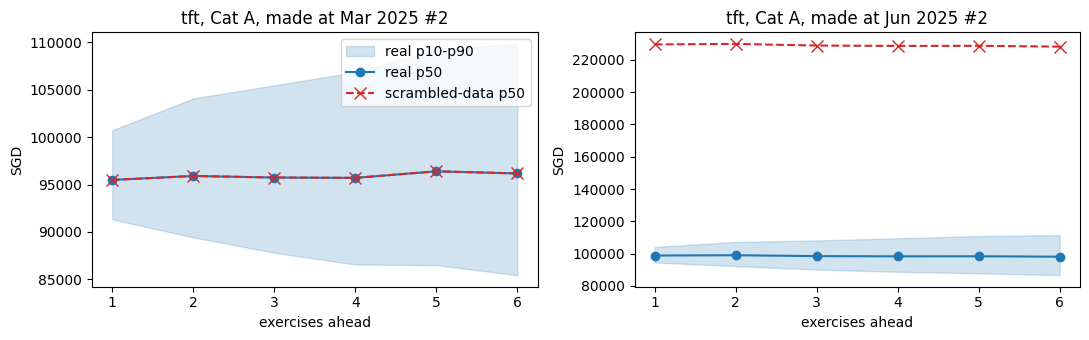

In [17]:
model = "tft" if "tft" in MODELS else MODELS[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=False)
origins = sorted(both["origin"].unique())
before = max(o for o in origins if o <= cut)          # forecasts are made every origin_stride exercises
after = min(o for o in origins if o > cut)
for ax, origin in zip(axes, (before, after)):
    d = both[(both["model"] == model) & (both["category"] == "A") & (both["origin"] == origin)]
    ax.fill_between(d["horizon"], d["q10"], d["q90"], color="tab:blue", alpha=.2, label="real p10-p90")
    ax.plot(d["horizon"], d["q50"], "o-", color="tab:blue", label="real p50")
    ax.plot(d["horizon"], d["q50_s"], "x--", color="tab:red", ms=9, label="scrambled-data p50")
    ax.set(title=f"{model}, Cat A, made at {label(origin)}", xlabel="exercises ahead", ylabel="SGD")
axes[0].legend(); plt.tight_layout(); plt.show()

## Part 2 — Fairness statistics

`fairness_stats.report(df)` takes a table of backtest predictions and prints:

0. **integrity**: the random walk's forecast must equal the premium on the day it was made
1. pooled scores and **skill** vs the random walk ("next premium = today's premium")
2. a **95% confidence interval** of that skill (block bootstrap: resample runs of 6 consecutive forecast dates, because neighbouring forecasts overlap)
3. skill **per test year** (is the gain stable?)
4. **calibration**: do 10% of actuals fall below p10, 50% below p50, 10% above p90?
5. **error by horizon**: honest forecasts get worse the further ahead they look

### 2.1 Get predictions
`SOURCE = "database"` reads the full production backtest from the running Docker stack (the same numbers as the website's Model page). `SOURCE = "part1"` uses the quick backtest from Part 1 instead (no Docker needed, but fewer epochs and no hybrid model, so the numbers are lower quality).

In [18]:
SOURCE = "database"     # or "part1"
RUN_ID = None           # None = latest successful run
DB_CONTAINER = "coe-forecast-db-1"

import subprocess

def load_from_docker(run_id=None):
    """Run fairness_stats.QUERY inside the Postgres container (the database port is not exposed to the laptop)."""
    def psql(sql):
        out = subprocess.run(["docker", "exec", DB_CONTAINER, "psql", "-U", "coe", "-d", "coe", "-c", sql],
                             capture_output=True, text=True, check=True)
        return out.stdout
    if run_id is None:
        run_id = int(psql("COPY (SELECT max(id) FROM model_runs WHERE status = 'succeeded') TO STDOUT").strip())
    query = fairness_stats.QUERY.replace(":run_id", str(int(run_id)))
    from io import StringIO
    return run_id, pd.read_csv(StringIO(psql(f"COPY ({query}) TO STDOUT WITH CSV HEADER")), parse_dates=["month"])

if SOURCE == "database":
    try:
        RUN_ID, preds = load_from_docker(RUN_ID)
        print(f"run {RUN_ID} from the database")
    except (subprocess.CalledProcessError, FileNotFoundError, ValueError) as err:
        print(f"could not read the database ({err}); using Part 1 instead")
        SOURCE = "part1"
if SOURCE == "part1":
    preds = real.copy()
preds.head()

run 1 from the database


,run_id,model,category,origin,horizon,month,bidding_no,actual,q10,q50,q90,origin_premium
0,1,tft,A,325,1,2023-11-01,1,95689,103345.593879,107486.933316,112977.787280,106000
1,1,tft,A,325,2,2023-11-01,2,85001,102054.566320,108405.495233,117141.225990,106000
2,1,tft,A,325,3,2023-12-01,1,88020,100955.360534,108813.456539,119572.395069,106000
3,1,tft,A,325,4,2023-12-01,2,85000,100367.261514,109328.529226,121881.352928,106000
4,1,tft,A,325,5,2024-01-01,1,65010,99828.018005,109827.610645,123980.499024,106000


### 2.2 The report

In [19]:
fairness_stats.report(preds)

16080 predictions, 67 origins, Nov 2023 - Oct 2026

0. Integrity: random-walk median == origin premium in 100.0% of rows

1. Pooled scores
                 pinball      mae  mape  skill_vs_rw_%
model                                                
hybrid          1832.39  5205.70  6.44           1.23
naive           1855.19  5332.78  6.52           0.00
lstm            1857.84  5292.98  6.68          -0.14
tft             1866.76  5327.69  6.72          -0.62
arima           1878.75  5324.30  6.50          -1.27
tft_no_policy   1890.01  5378.02  6.80          -1.88
arimax_boxtiao  1899.12  5381.28  6.54          -2.37
gbm             2057.08  5965.23  7.18         -10.88

2. Skill vs random walk, 95% block-bootstrap CI (positive = better than random walk)
   arima            -1.27%  CI [ -4.29%,  +1.10%]  P(better)=0.13
   arimax_boxtiao   -2.37%  CI [ -4.88%,  -0.58%]  P(better)=0.01
   gbm             -10.88%  CI [-24.22%, +11.18%]  P(better)=0.21
   hybrid           +1.23%  CI [ -1.

### 2.3 The same in pictures

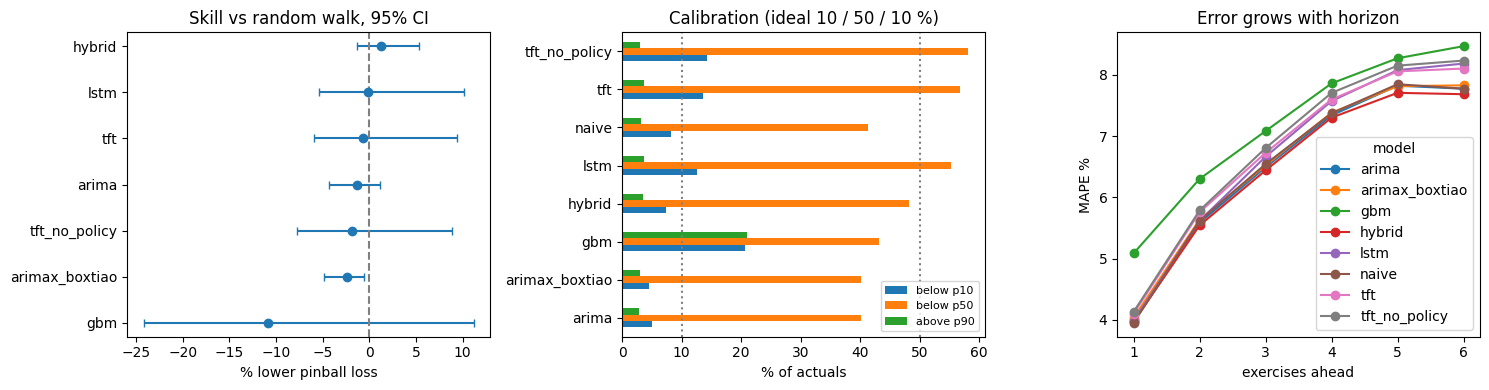

In [20]:
preds["loss"] = fairness_stats.pinball(preds)
per_origin = preds.pivot_table(index="origin", columns="model", values="loss", aggfunc="mean")
rw = per_origin.pop("naive").to_numpy()
idx = fairness_stats.block_indices(len(rw), np.random.default_rng(0))
ci = pd.DataFrame({m: [(1 - per_origin[m].mean() / rw.mean()) * 100,
                       *np.percentile([(1 - per_origin[m].to_numpy()[i].mean() / rw[i].mean()) * 100 for i in idx], [2.5, 97.5])]
                   for m in per_origin}, index=["mid", "lo", "hi"]).T.sort_values("mid")

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4))
a1.errorbar(ci["mid"], ci.index, xerr=[ci["mid"] - ci["lo"], ci["hi"] - ci["mid"]], fmt="o", capsize=3)
a1.axvline(0, color="grey", ls="--"); a1.set(title="Skill vs random walk, 95% CI", xlabel="% lower pinball loss")

cal = pd.DataFrame({"below p10": preds.actual < preds.q10, "below p50": preds.actual < preds.q50,
                    "above p90": preds.actual > preds.q90}).groupby(preds["model"]).mean() * 100
cal.plot.barh(ax=a2); a2.legend(loc="lower right", fontsize=8); [a2.axvline(v, color="grey", ls=":") for v in (10, 50)]
a2.set(title="Calibration (ideal 10 / 50 / 10 %)", xlabel="% of actuals", ylabel="")

mape = preds.assign(ape=(preds.q50 - preds.actual).abs() / preds.actual * 100).pivot_table(
    index="horizon", columns="model", values="ape")
mape.plot(ax=a3, marker="o"); a3.set(title="Error grows with horizon", xlabel="exercises ahead", ylabel="MAPE %")
plt.tight_layout(); plt.show()

## Part 3 — Test your own script

Three ways to use this notebook for your own work. Put your script in `ml/scripts/`.

### 3.1 Run a script exactly as on the command line
`run_script()` runs it from the `ml/` folder, shows its output and says whether it succeeded (exit code 0).

In [21]:
def run_script(script, *args, timeout=1800):
    """Run `python <script> <args>` from the ml/ folder and print its output."""
    started = time.time()
    result = subprocess.run([sys.executable, script, *map(str, args)], cwd=ML_DIR,
                            capture_output=True, text=True, timeout=timeout)
    print(result.stdout[-20000:])
    if result.returncode:
        print(result.stderr[-5000:])
    print(f"--- {script}: {'OK' if result.returncode == 0 else f'FAILED (exit {result.returncode})'} in {time.time() - started:.0f} s")
    return result.returncode

run_script("scripts/predictability.py")        # change to your script, e.g. run_script("scripts/my_script.py", "arg1")

h=1: out-of-sample R^2 vs random walk +0.020, direction 57.6%
    corr(mom1          , change) train -0.07   test -0.12
    corr(mom3          , change) train -0.12   test -0.14
    corr(mom6          , change) train -0.11   test -0.13
    corr(bid_ratio     , change) train +0.05   test +0.02
    corr(bid_ratio_chg , change) train +0.07   test +0.13
    corr(quota_chg_q   , change) train +0.05   test -0.14
    corr(success_ratio , change) train +0.06   test +0.01
h=3: out-of-sample R^2 vs random walk +0.009, direction 60.5%
    corr(mom1          , change) train -0.11   test -0.13
    corr(mom3          , change) train -0.17   test -0.08
    corr(mom6          , change) train -0.14   test -0.16
    corr(bid_ratio     , change) train +0.03   test -0.02
    corr(bid_ratio_chg , change) train +0.04   test -0.05
    corr(quota_chg_q   , change) train +0.01   test -0.25
    corr(success_ratio , change) train +0.04   test +0.10
h=6: out-of-sample R^2 vs random walk +0.030, direction 61.6%
  

0

Scripts that need the **database** (like `fairness_stats.py` itself) must run inside Docker, because Postgres is only reachable from the Docker network:

In [22]:
def run_in_docker(script, *args):
    """Run an ml/scripts/ file inside the ml container, next to the database."""
    cmd = ["docker", "compose", "run", "--rm", "-v", "./ml/scripts:/app/scripts", "--entrypoint", "python",
           "ml", script, *map(str, args)]
    result = subprocess.run(cmd, cwd=ML_DIR.parent, capture_output=True, text=True)
    print(result.stdout[-20000:] or result.stderr[-5000:])
    return result.returncode

# run_in_docker("scripts/fairness_stats.py")     # uncomment to try (Docker stack must be running)

### 3.2 Import your script and call its functions
Because of autoreload (Setup), you can edit `ml/scripts/my_script.py`, save, and re-run the cell. Give your script a `main()` and keep the work in small functions, like `leakage_test.py`, so you can call them one at a time and inspect the results.

In [23]:
# import my_script
# result = my_script.some_function(panel)
# result.head()

### 3.3 Check a new model for leakage and fairness
If you add a model to `coe_ml/evaluation.py` (in `MODEL_LABELS` and `backtest()`), test it with the same checks:

In [24]:
# leakage_test.main(["my_model", "naive"])       # PASS / LEAK, ~1-5 min
#
# If your script produces its own predictions table, the stats work on it too. It needs the columns
#   model, category, origin, horizon, month, actual, q10, q50, q90, origin_premium
# and must include the random walk (model == "naive") as the benchmark:
# fairness_stats.report(my_predictions)